In [22]:
from langchain.chat_models import init_chat_model
import langchain_ollama

In [23]:
from langchain.tools import tool

In [24]:
from dataclasses import dataclass
from typing import TypedDict, Optional, Set, List

In [25]:
from rich.console import Console
from rich.panel import Panel
from rich.pretty import Pretty
console = Console()

In [26]:
model = init_chat_model(
    model="qwen3:8b",
    model_provider="ollama",
    temprature = 0
)

In [27]:
def show(stuff : str):
    console.print(Panel(Pretty(stuff)))
    

In [28]:
from pydantic import BaseModel, Field
class SearchQuery(BaseModel):
    search_query : str = Field(None, description="Query that is optimised web search")
    justification: str = Field(None,justification = "Why tis query is relavent to the user prompt")

structured_llm = model.with_structured_output(SearchQuery)

output = model.invoke("Who is Spiderman")
console.print(Panel(Pretty(output), title="LLM output"))

C:\Users\advai\AppData\Local\Temp\ipykernel_8408\2565705925.py:4: PydanticDeprecatedSince20: Using extra keyword arguments on `Field` is deprecated and will be removed. Use `json_schema_extra` instead. (Extra keys: 'justification'). Deprecated in Pydantic V2.0 to be removed in V3.0. See Pydantic V2 Migration Guide at https://errors.pydantic.dev/2.14/migration/
  justification: str = Field(None,justification = "Why tis query is relavent to the user prompt")


╭────────────────────────────────────────────────── LLM output ───────────────────────────────────────────────────╮
│ AIMessage(                                                                                                      │
│     content='**Spider-Man** (real name: **Peter Parker**) is a fictional superhero and a central character in   │
│ the **Marvel Comics** universe. Created by **Stan Lee** and **Steve Ditko**, the character first appeared in    │
│ *Amazing Fantasy #15* (1962). Here\'s a concise overview:\n\n---\n\n### **Origin Story**\n- **Peter Parker** is │
│ a high school student in New York City who gains superpowers after being bitten by a **radioactive spider**     │
│ (originally a **mutant spider** in early stories, later reimagined as a **radioactive spider**).\n- His powers  │
│ include:\n  - **Superhuman strength, agility, and reflexes**\n  - **Wall-crawling**\n  - **Enhanced senses**    │
│ (spider-sense, which warns him of danger)\n  - **Web-shooters** (customized to fire sticky webbing for swinging │
│ between buildings and creating traps)\n\n---\n\n### **Personality and Themes**\n- **Relatable and flawed**:     │
│ Peter balances his responsibilities as a hero with his personal life, including school, relationships, and      │
│ financial struggles.\n- **"With great power comes great responsibility"**: A mantra he adopts after Uncle       │
│ Ben\'s death, emphasizing the ethical use of his abilities.\n- **Sarcastic and witty**: His humor and           │
│ self-deprecating attitude make him a fan favorite.\n\n---\n\n### **Role in the Marvel Universe**\n- **Avengers  │
│ member**: He joins the Avengers, though his role has evolved over time (e.g., as a founding member in some      │
│ storylines).\n- **Spider-Verse**: A multiverse storyline where Spider-Man variants from different realities     │
│ team up to face threats.\n- **Lorekeeper**: In some arcs, he becomes a guardian of the multiverse, taking on a  │
│ more cosmic role.\n\n---\n\n### **Media Adaptations**\n- **Comics**: Spider-Man has been featured in numerous   │
│ series, including *The Amazing Spider-Man*, *Ultimate Spider-Man*, and *Spider-Verse*.\n- **Movies**: \n  -     │
│ **Tobey Maguire** (2002–2007 films)\n  - **Andrew Garfield** (2012–2014 films)\n  - **Tom Holland**             │
│ (2016–present; *Spider-Man: Homecoming*, *Far From Home*, *No Way Home*)\n- **TV**: *Spider-Man: Into the       │
│ Spider-Verse* (2018, animated) and *Spider-Man: Web of Shadows* (2008).\n- **Other media**: Video games,        │
│ Broadway musicals, and even a *Spider-Man: Across the Spider-Verse* sequel (2023).\n\n---\n\n### **Cultural     │
│ Impact**\n- **Iconic symbol**: Spider-Man is one of Marvel\'s most recognizable characters, representing        │
│ resilience, humility, and the idea that anyone can be a hero.\n- **Influence**: His character has inspired      │
│ countless stories, merchandise, and pop culture references.\n\n---\n\n### **Variants and Reboots**\n-           │
│ **Ultimate Spider-Man**: A reimagined version with a more modern, gritty tone.\n- **Superior Spider-Man**: A    │
│ storyline where Peter\'s mind is taken over by the alien **Kaine**, leading to a darker, more powerful          │
│ version.\n- **Spider-Man: Across the Spider-Verse**: Explores multiverse themes and introduces new              │
│ Spider-Characters (e.g., Spider-Gwen, Spider-India).\n\n---\n\nSpider-Man\'s enduring appeal lies in his        │
│ relatability, moral complexity, and the timeless message that heroism is about choices, not just powers. 🕷️',   │
│     additional_kwargs={},                                                                                       │
│     response_metadata={                                                                                         │
│         'model': 'qwen3:8b',                                                                                    │
│         'created_at': '2026-10-09T19:21:41.516017Z',  

In [29]:
@tool 
def multiply(a:int , b:int) -> int:
    """multiply two numbers """
    return a + b

llm_with_tools = model.bind_tools([multiply])
ans = llm_with_tools.invoke("What is 2 times 3 ")
display(ans)

AIMessage(content='', additional_kwargs={}, response_metadata={'model': 'qwen3:8b', 'created_at': '2026-10-09T19:21:46.6145831Z', 'done': True, 'done_reason': 'stop', 'total_duration': 5069956200, 'load_duration': 181152900, 'prompt_eval_count': 141, 'prompt_eval_duration': 97164500, 'eval_count': 163, 'eval_duration': 4678122500, 'logprobs': None, 'model_name': 'qwen3:8b', 'model_provider': 'ollama'}, id='lc_run--01a1221d-33a7-7653-8120-916b069584b8-0', tool_calls=[{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'fb15ec07-2dfd-4027-97cd-9ffcc6af5e72', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 141, 'output_tokens': 163, 'total_tokens': 304})

### Joke workFlow 

In [30]:
# State
class Joke(TypedDict):
    topic: str
    joke: str
    improved_joke: str
    Final_joke: str



In [31]:
# Nodes
def generate_joke(state: Joke):
    msg = model.invoke(f"Write a short joke about {state["topic"]}")
    return {"joke" : msg.content} 
def improve_joke(state: Joke):
    msg = model.invoke(f"Make this joke Funnier by adding puns {state["joke"]}")
    return {"improved_joke" : msg.content}
def polish_joke(state: Joke):
    msg = model.invoke(f"Add a suprising twist to the joke {state["improved_joke"]}")
    return {"Final_joke" : msg.content}

#Gate
def check_pun(state : Joke):
    """ Checks the ? and ! in the Joke for the element of suprize """
    if "?" in state["joke"] or "!" in state["joke"]:
        return "Pass"
    return "Fail"

In [32]:
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display

In [33]:
# Nodes 
joke_workflow = StateGraph(Joke)
joke_workflow.add_node("generate_joke", generate_joke)
joke_workflow.add_node("improve_joke", improve_joke)
joke_workflow.add_node("polish_joke", polish_joke)

#Edges
joke_workflow.add_edge(START, "generate_joke")
joke_workflow.add_conditional_edges("generate_joke", check_pun,{"Pass": "improve_joke", "Fail": END})
joke_workflow.add_edge("improve_joke", "polish_joke")
joke_workflow.add_edge("polish_joke", END)


chain = joke_workflow.compile()


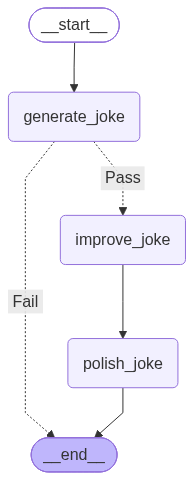

In [35]:
display(Image(chain.get_graph().draw_mermaid_png()))

In [ ]:
state = chain.invoke({"topic": "owl"})
print("Initial Joke")
show(state["joke"])
if improve_joke in state:
    print("Improved Joke")
    show(state["improve_joke"])
    print("Final Joke")
    show(["Final_joke"])


Initial Joke


╭─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╮
│ __main__.Joke['joke']                                                                                           │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

TypeError: argument of type '_TypedDictMeta' is not a container or iterable